## 4. Audio preprocessing and spectrogram creation
All clips are made exactly one second long. Spectrograms are generated with an STFT and log-scaled. We use the same preprocessing for training and both model comparisons.

Spectrogram batch shape: (32, 124, 129, 1) labels shape: (32,)


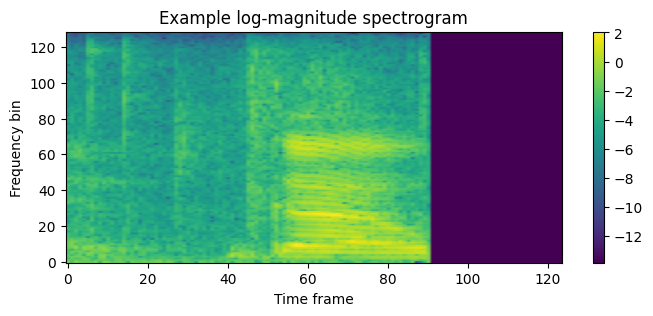

In [14]:
FRAME_LENGTH = 256
FRAME_STEP = 128
FFT_LENGTH = 256

def load_audio(path, label):
    audio_bytes = tf.io.read_file(path)
    audio, sr = tf.audio.decode_wav(audio_bytes, desired_channels=1)
    audio = tf.squeeze(audio, axis=-1)
    audio = tf.cast(audio, tf.float32)

    # The mini_speech_commands WAV files are 16 kHz. Fail clearly if that changes.
    tf.debugging.assert_equal(
        tf.cast(sr, tf.int32), SAMPLE_RATE,
        message="Expected 16 kHz audio in mini_speech_commands."
    )
    audio = audio[:AUDIO_LENGTH]
    padding = tf.maximum(0, AUDIO_LENGTH - tf.shape(audio)[0])
    audio = tf.pad(audio, [[0, padding]])
    audio.set_shape([AUDIO_LENGTH])

    stft = tf.signal.stft(audio, frame_length=FRAME_LENGTH,
                          frame_step=FRAME_STEP, fft_length=FFT_LENGTH)
    spec = tf.abs(stft)
    spec = tf.math.log(spec + 1e-6)
    spec = spec[..., tf.newaxis]
    return spec, tf.cast(label, tf.int32)

def make_ds(p, y, training=False):
    ds = tf.data.Dataset.from_tensor_slices((p, y))
    if training:
        ds = ds.shuffle(len(p), seed=SEED, reshuffle_each_iteration=True)
    ds = ds.map(load_audio, num_parallel_calls=AUTOTUNE)
    ds = ds.batch(32).prefetch(AUTOTUNE)
    return ds

train_ds = make_ds(train_paths, y_train, training=True)
val_ds = make_ds(val_paths, y_val)
test_ds = make_ds(test_paths, y_test)

for xb, yb in train_ds.take(1):
    print("Spectrogram batch shape:", xb.shape, "labels shape:", yb.shape)
    plt.figure(figsize=(8, 3))
    plt.imshow(xb[0, :, :, 0].numpy().T, aspect="auto", origin="lower")
    plt.title("Example log-magnitude spectrogram")
    plt.xlabel("Time frame")
    plt.ylabel("Frequency bin")
    plt.colorbar()
    plt.show()

## 6. Plot training curves and evaluate the FP32 baseline

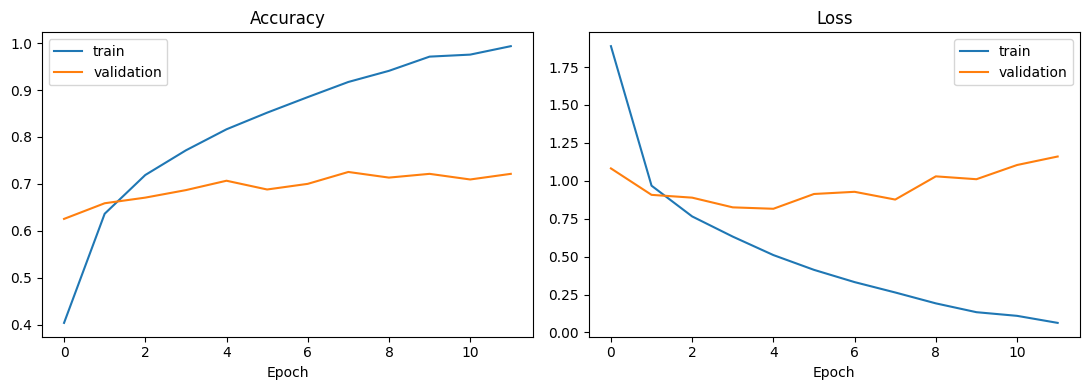

FP32 Keras test accuracy: 0.7120


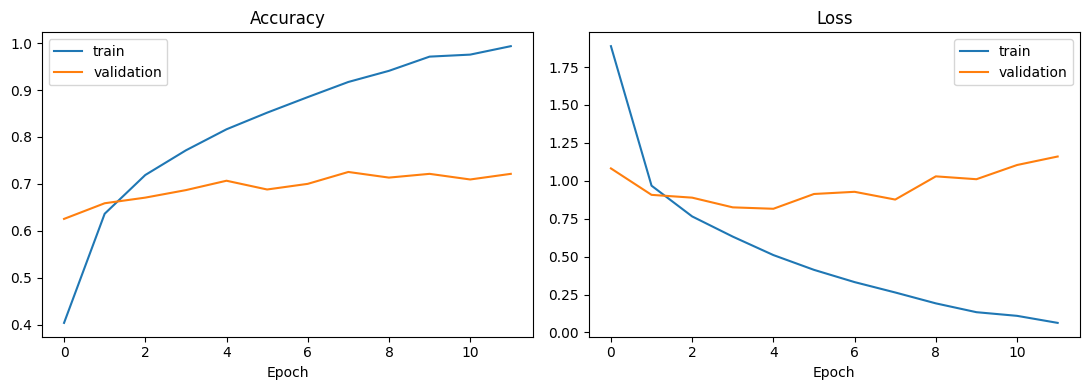

FP32 Keras test accuracy: 0.7120


In [16]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(history.history["accuracy"], label="train")
ax[0].plot(history.history["val_accuracy"], label="validation")
ax[0].set_title("Accuracy"); ax[0].set_xlabel("Epoch"); ax[0].legend()
ax[1].plot(history.history["loss"], label="train")
ax[1].plot(history.history["val_loss"], label="validation")
ax[1].set_title("Loss"); ax[1].set_xlabel("Epoch"); ax[1].legend()
plt.tight_layout(); plt.show()

fp32_loss, fp32_keras_acc = model.evaluate(test_ds, verbose=0)
print(f"FP32 Keras test accuracy: {fp32_keras_acc:.4f}")

## 10. Comparing FP32 TFLite and INT8 TFLite on exactly the same test samples
This evaluates the exported models, not just the original Keras model.

In [22]:
# Materialize the test spectrograms and labels once for paired comparisons.
X_test_list, y_test_list = [], []
for xb, yb in test_ds:
    X_test_list.extend(xb.numpy())
    y_test_list.extend(yb.numpy())
X_test = np.asarray(X_test_list, dtype=np.float32)
y_test_np = np.asarray(y_test_list, dtype=np.int64)

def batch_predict(interpreter, X, integer_model=False):
    return np.stack([predict_one(interpreter, x, integer_model) for x in X])

fp32_probs = batch_predict(fp32_interpreter, X_test, integer_model=False)
int8_probs = batch_predict(int8_interpreter, X_test, integer_model=True)
fp32_pred = np.argmax(fp32_probs, axis=1)
int8_pred = np.argmax(int8_probs, axis=1)

fp32_acc = float(np.mean(fp32_pred == y_test_np))
int8_acc = float(np.mean(int8_pred == y_test_np))
agreement = float(np.mean(fp32_pred == int8_pred))

print(f"FP32 TFLite test accuracy: {fp32_acc:.4f}")
print(f"INT8 TFLite test accuracy: {int8_acc:.4f}")
print(f"Prediction agreement:      {agreement:.4f}")
print(f"Accuracy change (INT8-FP32): {(int8_acc-fp32_acc)*100:.2f} percentage points")
print("\nINT8 classification report:")
print(classification_report(y_test_np, int8_pred, target_names=LABELS, zero_division=0))

FP32 TFLite test accuracy: 0.2000
INT8 TFLite test accuracy: 0.7093
Prediction agreement:      0.2040
Accuracy change (INT8-FP32): 50.93 percentage points

INT8 classification report:
              precision    recall  f1-score   support

          no       0.61      0.63      0.62       150
         yes       0.86      0.91      0.88       150
        down       0.63      0.65      0.64       150
          go       0.63      0.63      0.63       150
          up       0.83      0.73      0.78       150

    accuracy                           0.71       750
   macro avg       0.71      0.71      0.71       750
weighted avg       0.71      0.71      0.71       750



## 11. Confusion matrices

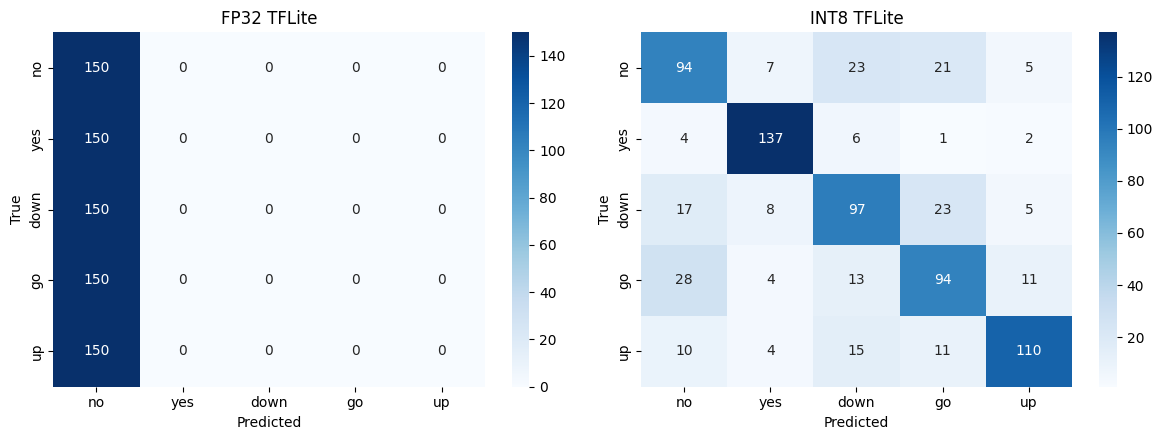

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, pred, title in [
    (axes[0], fp32_pred, "FP32 TFLite"),
    (axes[1], int8_pred, "INT8 TFLite")
]:
    cm = confusion_matrix(y_test_np, pred, labels=np.arange(len(LABELS)))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
                xticklabels=LABELS, yticklabels=LABELS, ax=ax)
    ax.set_title(title); ax.set_xlabel("Predicted"); ax.set_ylabel("True")
plt.tight_layout()
plt.savefig("artifacts/confusion_matrices.png", dpi=160, bbox_inches="tight")
plt.show()

## 14. Plot the comparison

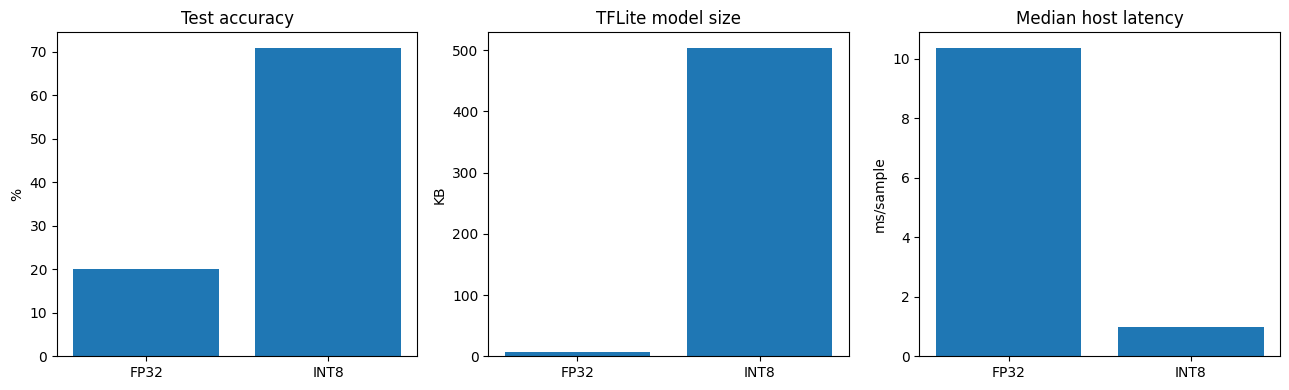

In [26]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4))
names = ["FP32", "INT8"]
axes[0].bar(names, [fp32_acc*100, int8_acc*100])
axes[0].set_title("Test accuracy"); axes[0].set_ylabel("%")
axes[1].bar(names, [fp32_size/1024, int8_size/1024])
axes[1].set_title("TFLite model size"); axes[1].set_ylabel("KB")
axes[2].bar(names, [fp32_ms, int8_ms])
axes[2].set_title("Median host latency"); axes[2].set_ylabel("ms/sample")
plt.tight_layout()
plt.savefig("artifacts/fp32_vs_int8_comparison.png", dpi=160, bbox_inches="tight")
plt.show()